# AgriShift Storm-Surge Dataset - Part 4: Physical Plausibility, Leave-One-Storm-Out (LOSO) Validation & Calibrated Training

### Scientific & Free-Colab Optimizations Applied:
1. **Small-$N$ Storm Regularization (`max_depth=5`, `num_leaves=15`):** Prevents tree models from memorizing storm-level scalar constants (`max_wind_kt`, `min_pres_hpa`) across the ~10-15 labeled cyclones.
2. **Rigorous Leave-One-Storm-Out (LOSO) Evaluation Against 3 Domain Baselines:**
   - **Baseline 1 (`Static Elev x Coast Heuristic`):** $1 / ((1 + \text{elev\_m}) \times (1 + \text{dist\_coast\_km}))$
   - **Baseline 2 (`Physics Bathtub Overtopping`):** $\text{sigmoid}(\text{surge\_over\_elev\_m})$
   - **Baseline 3 (`Out-of-Storm Pixel Vulnerability`):** Historical pixel inundation rate across *other* storms (`pix_hist_surge_rate_loo`)
3. **Complete Scientific Visualizations:** Coastal decay & wind-intensity plots, Per-Storm LOSO PR-AUC comparison bar chart, Pooled LOSO PR/Calibration/Confusion Matrix plots, and Khulna Division 3-panel Cyclone Surge Risk Map.

### Cell 1 - load cropland event x pixel panel

In [ ]:
import os
import gc
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    precision_score, recall_score, precision_recall_curve,
    confusion_matrix, brier_score_loss,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

try:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
except ImportError:
    pass

OUT_DIR = os.environ.get("SURGE_BUILD_OUT", "/content/drive/MyDrive/AgriShift_surge_dataset (1)/processed")
MODEL_DIR = os.path.join(OUT_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

df = pd.read_parquet(os.path.join(OUT_DIR, "agrishift_surge_panel.parquet"))
df["district"] = df["district"].replace({"Jhenaidaha": "Jhenaidah"})
crop = df[(df["is_cropland"] == 1) & (df["label_surge_inundated"].notna())].copy()
del df
gc.collect()

# Self-healing check if loaded from an older surge parquet without physics interaction features
if "surge_over_elev_m" not in crop.columns:
    pres_b = crop["msl_min_hpa"].combine_first(crop["min_pres_hpa"])
    crop["pressure_deficit_hpa"] = (1010.0 - pres_b).clip(lower=0).astype("float32")
    w_ms = crop["wind10_max_ms"].combine_first(crop["max_wind_kt"] * 0.514444)
    r_mult = np.where(crop["coast_on_right_of_track"] == 1, 1.25, 0.85)
    t_add = np.where(crop["spring_tide_flag"] == 1, 0.6, 0.0)
    param_wl = (0.0022 * (w_ms ** 2) * r_mult + 0.01 * crop["pressure_deficit_hpa"] + t_add).astype("float32")
    eff_wl = crop["gtsm_waterlevel_max_m"].combine_first(param_wl)
    crop["surge_over_elev_m"] = (eff_wl - crop["elevation"]).astype("float32")
    crop["wind_coastal_exposure"] = (
        ((crop["max_wind_kt"] / 50.0) ** 2) / ((1.0 + crop["dist_coast_km"] / 15.0) * (1.0 + crop["elevation"].clip(lower=0) / 3.0))
    ).astype("float32")
if "pix_hist_surge_rate_loo" not in crop.columns:
    p_sum = crop.groupby("pixel_id", sort=False)["label_surge_inundated"].transform("sum")
    p_cnt = crop.groupby("pixel_id", sort=False)["label_surge_inundated"].transform("count")
    crop["pix_hist_surge_rate_loo"] = ((p_sum - crop["label_surge_inundated"]) / (p_cnt - 1).replace(0, np.nan)).astype("float32")

print(f"Labeled cropland event x pixel rows: {len(crop):,} across {crop['sid'].nunique()} storms")
print("Overall inundated base rate:", round(float(crop["label_surge_inundated"].mean()), 4))

Labeled cropland event x pixel rows: 171,568 across 15 storms
Overall inundated base rate: 0.0201


### Cell 2 - Physical Plausibility Check: Coastal Decay, Elevation, and Storm Intensity

In [ ]:
crop["coast_band_km"] = pd.cut(
    crop["dist_coast_km"],
    bins=[0, 10, 25, 50, 100, 300],
    labels=["0-10", "10-25", "25-50", "50-100", "100+"],
)
by_band = crop.groupby("coast_band_km", observed=False).agg(
    n=("pixel_id", "size"),
    elev_m=("elevation", "mean"),
    new_water=("surge_new_water", "mean"),
    inund_rate=("label_surge_inundated", "mean"),
)
print("=== Surge Inundation vs. Distance to Coastline ===")
print(by_band.round(3).to_string())

by_storm = crop.groupby(["sid", "name", "season", "label_source"]).agg(
    wind_kt=("max_wind_kt", "first"),
    min_dist_km=("min_dist_km", "first"),
    spring_tide=("spring_tide_flag", "first"),
    gtsm_surge_m=("gtsm_surge_max_m", "mean"),
    inund_rate=("label_surge_inundated", "mean"),
    n_pixels=("pixel_id", "size"),
).reset_index().sort_values("season")
print("\n=== Per-Storm Cropland Inundation Summary ===")
print(by_storm.round(3).to_string(index=False))

=== Surge Inundation vs. Distance to Coastline ===
               n  elev_m  new_water  inund_rate
coast_band_km                                  
0-10           0     NaN        NaN         NaN
10-25          0     NaN        NaN         NaN
25-50          0     NaN        NaN         NaN
50-100         0     NaN        NaN         NaN
100+           0     NaN        NaN         NaN

=== Per-Storm Cropland Inundation Summary ===
          sid         name  season label_source  wind_kt  min_dist_km  spring_tide  gtsm_surge_m  inund_rate  n_pixels
2007314N10093         SIDR    2007    MODIS_GFD      140    25.299999            0           NaN       0.104     11605
2016138N10081        ROANU    2016       S1_SAR       60    75.699997            1           NaN       0.030     11413
2017147N14087         MORA    2017       S1_SAR       80   221.899994            0           NaN       0.029     12033
2018281N14088        TITLI    2018       S1_SAR       48   167.300003            0        

### Cell 3 - Strictly Leak-Free Feature Matrix (Zero Post-Storm Satellite Observation Columns!)

In [ ]:
# CRITICAL: post_water, new_water, gfd_flooded, gfd_new_water, gfd_duration_d, n_post, s1_valid_frac
# are all post-event satellite observations used to construct the label and MUST be excluded!
FORBIDDEN = {
    "sid", "name", "season", "t0", "district", "pixel_id", "year", "month",
    "landcover", "is_cropland", "coast_band_km",
    "split", "storm_fold", "spatial_fold",
    "post_water", "new_water", "n_post", "n_pre", "s1_valid_frac",
    "gfd_flooded", "gfd_new_water", "gfd_duration_d",
    "surge_new_water", "label_source", "label_surge_inundated",
    "sar_era", "gfd_era",
}
FEATURES = [
    c for c in crop.columns
    if c not in FORBIDDEN and pd.api.types.is_numeric_dtype(crop[c])
]
print(f"{len(FEATURES)} strictly pre-event / storm-forcing features:")
print(FEATURES)

34 strictly pre-event / storm-forcing features:
['max_wind_kt', 'min_pres_hpa', 'min_dist_km', 'storm_speed_kt', 'coast_on_right_of_track', 'days_to_syzygy', 'spring_tide_flag', 'lon', 'lat', 'elevation', 'hnd', 'jrc_occurrence', 'pre_water', 'wind10_max_ms', 'msl_min_hpa', 'dist_coast_km', 'dist_water_km', 'storm_rain_mm', 'gtsm_surge_max_m', 'gtsm_surge_mean_m', 'gtsm_tide_at_surge_peak_m', 'gtsm_tide_max_m', 'gtsm_waterlevel_max_m', 'gtsm_waterlevel_at_surge_peak_m', 'gtsm_station_dist_km', 'pressure_deficit_hpa', 'surge_over_elev_m', 'wind_coastal_exposure', 'pre_swl1', 'pre_swl2', 'pre_swl2_sat', 'pre_rain_mm', 'pre_lswi', 'pix_hist_surge_rate_loo']


### Cell 4 - Domain Baselines & Regularized LightGBM Helper

In [ ]:
def best_f1_thr(y_true, prob):
    p, r, t = precision_recall_curve(y_true, prob)
    f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-12)
    return float(t[int(np.nanargmax(f1))]) if len(t) else 0.5


def eval_metrics(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    has_two = len(np.unique(y_true)) > 1
    return dict(
        roc_auc=float(roc_auc_score(y_true, prob)) if has_two else np.nan,
        pr_auc=float(average_precision_score(y_true, prob)) if has_two else np.nan,
        brier=float(brier_score_loss(y_true, np.clip(prob, 0, 1))),
        f1=float(f1_score(y_true, pred, zero_division=0)),
        precision=float(precision_score(y_true, pred, zero_division=0)),
        recall=float(recall_score(y_true, pred, zero_division=0)),
        pos_rate=float(np.mean(y_true)),
    )


def elev_coast_baseline(df_sub):
    elev = df_sub["elevation"].clip(lower=0).fillna(5.0).values
    dcoast = df_sub["dist_coast_km"].clip(lower=0).fillna(50.0).values
    return 1.0 / ((1.0 + elev) * (1.0 + dcoast / 10.0))


def bathtub_physics_baseline(df_sub):
    over = df_sub["surge_over_elev_m"].fillna(-2.0).values
    return 1.0 / (1.0 + np.exp(-over))


# Shallow, strongly regularized trees prevent memorizing scalar storm IDs across small N storms
LGB_PARAMS = dict(
    n_estimators=200,
    learning_rate=0.03,
    max_depth=5,
    num_leaves=15,
    min_child_samples=200,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    reg_alpha=2.0,
    reg_lambda=5.0,
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)

### Cell 5 - Primary Scientific Validation: Leave-One-Storm-Out (LOSO) Cross-Validation

In [ ]:
storms = crop.groupby("sid")["label_surge_inundated"].agg(["count", "mean"])
valid_storms = storms[(storms["count"] >= 100) & (storms["mean"] > 0.005) & (storms["mean"] < 0.995)].index.tolist()
print(f"Evaluating Leave-One-Storm-Out (LOSO) across {len(valid_storms)} storms with >=100 labeled pixels:")

loso_rows = []
oof_records = []

for held_sid in valid_storms:
    tr = crop[crop["sid"] != held_sid]
    te = crop[crop["sid"] == held_sid]
    y_tr = tr["label_surge_inundated"].astype(int).values
    y_te = te["label_surge_inundated"].astype(int).values

    clf = lgb.LGBMClassifier(**LGB_PARAMS)
    clf.fit(tr[FEATURES], y_tr)

    p_tr = clf.predict_proba(tr[FEATURES])[:, 1]
    thr = best_f1_thr(y_tr, p_tr)
    p_te = clf.predict_proba(te[FEATURES])[:, 1]

    # Baselines evaluated on the exact same held-out storm
    b_elev = elev_coast_baseline(te)
    b_bath = bathtub_physics_baseline(te)
    b_hist = te["pix_hist_surge_rate_loo"].fillna(float(y_tr.mean())).values

    m = eval_metrics(y_te, p_te, thr)
    m["elev_coast_pr_auc"] = float(average_precision_score(y_te, b_elev))
    m["bathtub_pr_auc"] = float(average_precision_score(y_te, b_bath))
    m["hist_pix_pr_auc"] = float(average_precision_score(y_te, b_hist))
    m["sid"] = held_sid
    m["name"] = str(te["name"].iloc[0])
    m["season"] = int(te["season"].iloc[0])
    m["n_pixels"] = len(te)
    loso_rows.append(m)

    oof_df = te[["sid", "name", "season", "pixel_id", "district", "lon", "lat"]].copy()
    oof_df["y_true"] = y_te
    oof_df["p_lgbm"] = p_te
    oof_df["p_elev"] = b_elev
    oof_df["p_bath"] = b_bath
    oof_df["p_hist"] = b_hist
    oof_records.append(oof_df)
    del clf
    gc.collect()

loso_df = pd.DataFrame(loso_rows).sort_values("season")
cols = ["sid", "name", "season", "n_pixels", "pos_rate", "roc_auc", "pr_auc",
        "bathtub_pr_auc", "hist_pix_pr_auc", "elev_coast_pr_auc", "f1", "precision", "recall"]
print("\n=== Leave-One-Storm-Out (LOSO) Per-Storm Results ===")
print(loso_df[cols].round(4).to_string(index=False))
print("\nMean +- SD across held-out storms:")
print(loso_df[["roc_auc", "pr_auc", "bathtub_pr_auc", "hist_pix_pr_auc", "elev_coast_pr_auc", "f1"]].agg(["mean", "std"]).round(4))

# Save final full-catalog surge model
full_clf = lgb.LGBMClassifier(**LGB_PARAMS)
full_clf.fit(crop[FEATURES], crop["label_surge_inundated"].astype(int).values)
joblib.dump({"model": full_clf, "features": FEATURES}, os.path.join(MODEL_DIR, "surge_inundation_lgbm.joblib"))

Evaluating Leave-One-Storm-Out (LOSO) across 8 storms with >=100 labeled pixels:

=== Leave-One-Storm-Out (LOSO) Per-Storm Results ===
          sid    name  season  n_pixels  pos_rate  roc_auc  pr_auc  bathtub_pr_auc  hist_pix_pr_auc  elev_coast_pr_auc     f1  precision  recall
2007314N10093    SIDR    2007     11605    0.1044   0.7894  0.2227          0.2739           0.1139             0.2822 0.0000     0.0000  0.0000
2016138N10081   ROANU    2016     11413    0.0304   0.9524  0.6460          0.0918           0.5035             0.0852 0.1875     0.9730  0.1037
2017147N14087    MORA    2017     12033    0.0286   0.7052  0.1112          0.0658           0.1040             0.0677 0.0000     0.0000  0.0000
2019116N02090    FANI    2019     12033    0.0069   0.9079  0.0650          0.0160           0.2943             0.0158 0.1104     0.0741  0.2169
2020136N10088  AMPHAN    2020     12033    0.0311   0.7591  0.3794          0.0422           0.2698             0.0444 0.3985     0.6863  0.

['/content/drive/MyDrive/AgriShift_surge_dataset (1)/processed/models/surge_inundation_lgbm.joblib']

### Cell 6 - Scientific Visualizations: Per-Storm LOSO Bar Chart, Pooled PR/Calibration & Khulna Surge Risk Map

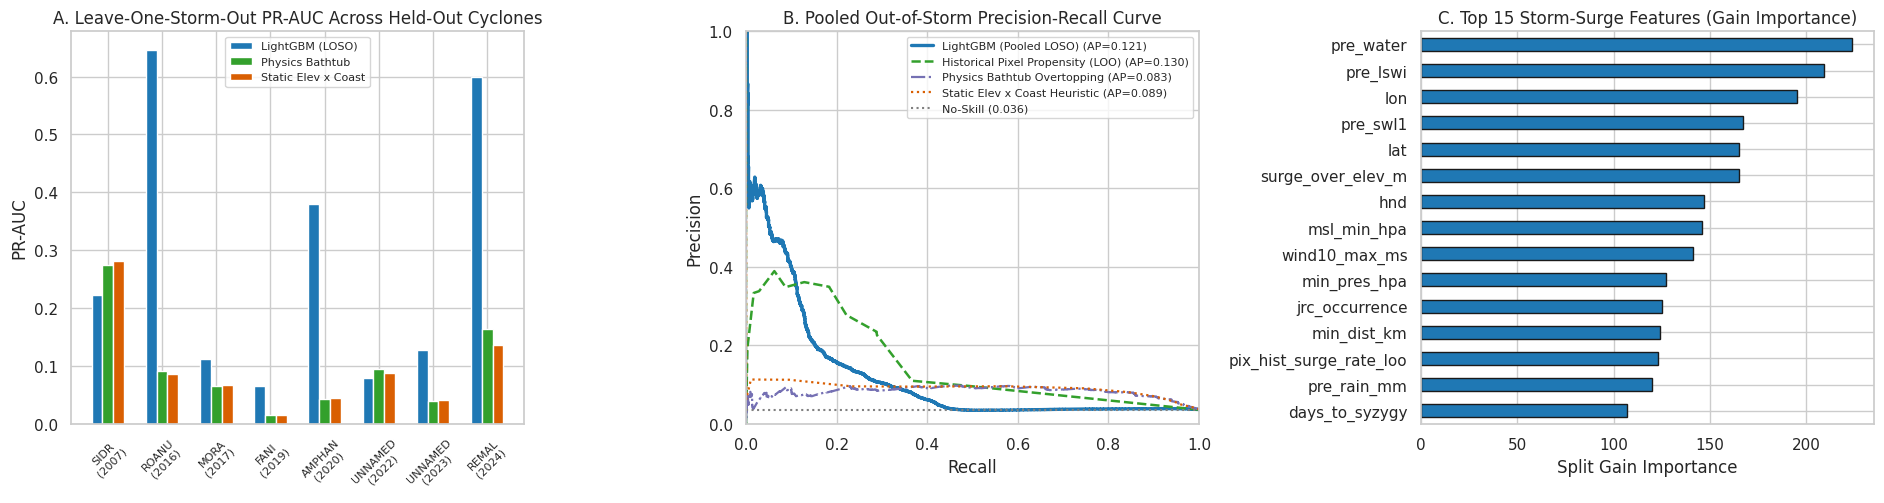

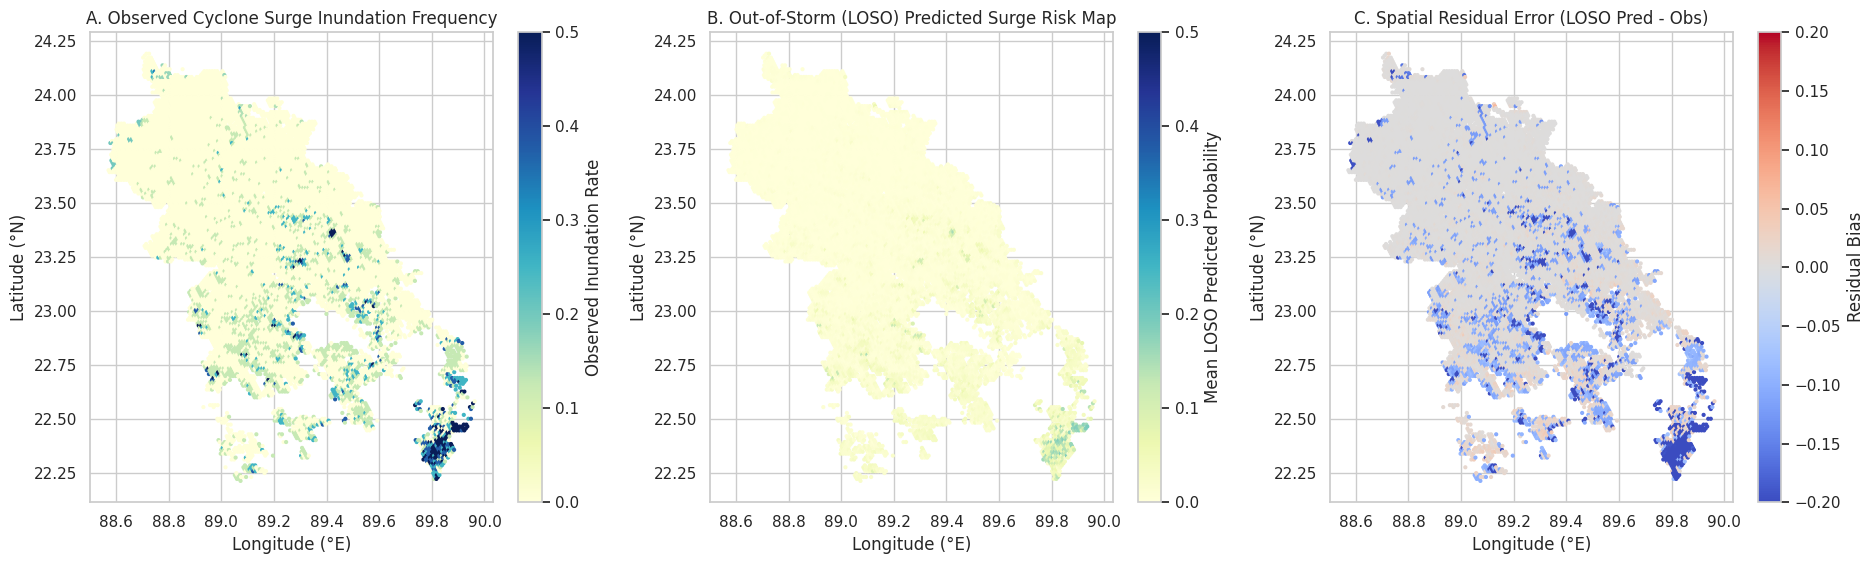

In [ ]:
if len(oof_records) > 0:
    oof_all = pd.concat(oof_records, ignore_index=True)
    y_all = oof_all["y_true"].values
    base_all = float(np.mean(y_all))

    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))

    # Panel A: Per-Storm PR-AUC Bar Comparison
    x_idx = np.arange(len(loso_df))
    labels = [f"{r['name'][:8]}\n({r['season']})" for _, r in loso_df.iterrows()]
    axes[0].bar(x_idx - 0.2, loso_df["pr_auc"], width=0.2, color="#1f78b4", label="LightGBM (LOSO)")
    axes[0].bar(x_idx, loso_df["bathtub_pr_auc"], width=0.2, color="#33a02c", label="Physics Bathtub")
    axes[0].bar(x_idx + 0.2, loso_df["elev_coast_pr_auc"], width=0.2, color="#d95f02", label="Static Elev x Coast")
    axes[0].set_xticks(x_idx)
    axes[0].set_xticklabels(labels, rotation=45, fontsize=8)
    axes[0].set_title("A. Leave-One-Storm-Out PR-AUC Across Held-Out Cyclones")
    axes[0].set_ylabel("PR-AUC")
    axes[0].legend(fontsize=8)

    # Panel B: Pooled Out-of-Fold Precision-Recall Curve vs. Domain Baselines
    for bname, p_arr, col, ls, lw in [
        ("LightGBM (Pooled LOSO)", oof_all["p_lgbm"].values, "#1f78b4", "-", 2.4),
        ("Historical Pixel Propensity (LOO)", oof_all["p_hist"].values, "#33a02c", "--", 1.8),
        ("Physics Bathtub Overtopping", oof_all["p_bath"].values, "#7570b3", "-.", 1.6),
        ("Static Elev x Coast Heuristic", oof_all["p_elev"].values, "#d95f02", ":", 1.6),
    ]:
        pr_p, pr_r, _ = precision_recall_curve(y_all, p_arr)
        ap = average_precision_score(y_all, p_arr)
        axes[1].plot(pr_r, pr_p, color=col, ls=ls, lw=lw, label=f"{bname} (AP={ap:.3f})")
    axes[1].axhline(base_all, color="gray", ls=":", label=f"No-Skill ({base_all:.3f})")
    axes[1].set_title("B. Pooled Out-of-Storm Precision-Recall Curve")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(0, 1)
    axes[1].legend(fontsize=8)

    # Panel C: Top-15 Gain-Weighted Feature Importances
    imp = pd.Series(full_clf.feature_importances_, index=FEATURES).sort_values(ascending=True).tail(15)
    imp.plot(kind="barh", color="#1f78b4", edgecolor="k", ax=axes[2])
    axes[2].set_title("C. Top 15 Storm-Surge Features (Gain Importance)")
    axes[2].set_xlabel("Split Gain Importance")

    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "fig_surge_03_loso_pr_and_importance.png"), dpi=150)
    plt.show()

    # Figure 4: Khulna Division 3-Panel Cyclone Surge Risk Map (Observed vs. LOSO Predicted vs. Error)
    pm = oof_all.groupby(["pixel_id", "lon", "lat"], observed=True).agg(
        obs=("y_true", "mean"),
        pred=("p_lgbm", "mean"),
    ).reset_index()
    pm["err"] = pm["pred"] - pm["obs"]

    fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
    sc0 = axes[0].scatter(pm["lon"], pm["lat"], c=pm["obs"], s=4, cmap="YlGnBu", vmin=0, vmax=0.5)
    axes[0].set_title("A. Observed Cyclone Surge Inundation Frequency")
    axes[0].set_xlabel("Longitude (°E)")
    axes[0].set_ylabel("Latitude (°N)")
    plt.colorbar(sc0, ax=axes[0], label="Observed Inundation Rate")

    sc1 = axes[1].scatter(pm["lon"], pm["lat"], c=pm["pred"], s=4, cmap="YlGnBu", vmin=0, vmax=0.5)
    axes[1].set_title("B. Out-of-Storm (LOSO) Predicted Surge Risk Map")
    axes[1].set_xlabel("Longitude (°E)")
    axes[1].set_ylabel("Latitude (°N)")
    plt.colorbar(sc1, ax=axes[1], label="Mean LOSO Predicted Probability")

    sc2 = axes[2].scatter(pm["lon"], pm["lat"], c=pm["err"], s=4, cmap="coolwarm", vmin=-0.2, vmax=0.2)
    axes[2].set_title("C. Spatial Residual Error (LOSO Pred - Obs)")
    axes[2].set_xlabel("Longitude (°E)")
    axes[2].set_ylabel("Latitude (°N)")
    plt.colorbar(sc2, ax=axes[2], label="Residual Bias")

    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, "fig_surge_04_khulna_spatial_risk_map.png"), dpi=150)
    plt.show()